# Ejemplo práctico de un modelo supervisado de clasificación
---

Autor: Manuel Díaz Bendito

---

El objetivo de este notebook, dado el dataset [Wine](https://archive.ics.uci.edu/dataset/109/wine), desarrollar un modelo de clasificación supervisado para ver si somos capaces de enternar un modeo que prediga los 3 tipos distintos de vino que hay presentes en los datos explorados. 

El desarrollo del notebook se compone de 4 pasos fundamentales:

* La carga, preparación y realización del Exploratory Data Analysis (EDA) de los datos.
* El procesado e ingeniería de características de estos datos.
* El entrenamiento del modelo de clasificación de los datos.
* La validación de los resultados obtenidos, y la conclusión final del desarrollo.

---

# 0 - Instalaciones necesarias e importación de librerías utilizadas

## Instalación de librerías
---
Además de la librería propia del dataset objeto de estudio, se ha instalado la librería de [XGBoost](https://xgboost.readthedocs.io/en/stable/index.html), al ser el modelo que se ha utilizado para el desarrollo (la elección de este modelo se desarrollará más adelante en este notebook), y la librería scikit-plot, utilizada para la evaluación del modelo.

Si durante la fase de importación, el usuario se encuentra con algún error de importación, deberá añadir la instalación de dicha librería en este bloque.

---

In [1]:
!pip install ucimlrepo


[notice] A new release of pip is available: 23.2.1 -> 25.1
[notice] To update, run: pip install --upgrade pip


In [2]:
!pip install xgboost


[notice] A new release of pip is available: 23.2.1 -> 25.1
[notice] To update, run: pip install --upgrade pip


---
Si tienes un macbook con chip sillicon, deberás ejectuar el sigueinte comando en el Terminal:

```bash
brew install libomp
```
---

In [3]:
!pip install scikit-plot


[notice] A new release of pip is available: 23.2.1 -> 25.1
[notice] To update, run: pip install --upgrade pip


## Importación de librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import random

from ucimlrepo import fetch_ucirepo

In [2]:
pd.options.display.max_columns = 100

# 1 - Carga, preparación y EDA de los datos

## 1.1 - Carga del dataset
---
La carga del dataset se realiza utilizando la librería desarrolada por la Universidad Pública de Irvine.

---

In [3]:
# fetch dataset
wine = fetch_ucirepo(id=109) 
  
# data (as pandas dataframes) 
df_train_raw = wine.data.features 
df_target_raw = wine.data.targets 


In [4]:
df_train_raw

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


## 1.2 - Preparación del dataset
---
En este punto, se unen datos y las etiquetas (descargados por separado en la carga del dataset).

---

In [5]:
# Imprimimos por pantalla cómo es la variable objetivo inicialmente.
df_target_raw.value_counts()

class
2        71
1        59
3        48
Name: count, dtype: int64

In [6]:
# Unimos datos y etiquetas en el mismo dataframe y aplicamos el mapeo de la variable objetivo.
df_train_raw['target'] = df_target_raw['class']

In [7]:
# Imprimimos por pantalla el nuevo target y su presencia (tanto por 1) en el dataset.
df_train_raw['target'].value_counts(normalize = True)

target
2    0.398876
1    0.331461
3    0.269663
Name: proportion, dtype: float64

## 1.3 - EDA
---
En este punto, se realiza el EDA del dataset propuesto. En este desarrollo, se ha dividido el EDA en dos puntos:
* Una exploración preliminar de las variables numéricas.
* Una exploración gráfica de las variables numéricas.

Como punto previo a todo el análisis, las variables sobre las que realizar el EDA son las siguientes (las definiciones son aproximaciones en cuanto al contexto y la documentación disponible):
* Alcohol: porcentaje de alcohol del vino - **numérica**
* Malicacid: concentración de ácido málico (un ácido orgánico natural) - **numérica**
* Ash: cantidad de cenizas (minerales) en el vino después de quemarlo - **numérica**
* Alcalinity_of_ash: alcalinidad de las cenizas (capacidad de neutralizar ácidos) - **numérica**
* Magnesium: contenido de magnesio (en partes por millón) - **numérica**
* Total_phenols: concentración total de compuestos fenólicos (afectan sabor y color) - **numérica**
* Flavanoids: subgrupo de fenoles relacionados al sabor y antioxidantes - **numérica**
* Nonflavanoid_phenols: otros fenoles que no son flavonoides - **numérica**
* Proanthocyanins: tipo de tanino (astringencia y color del vino) - **numérica**
* Color_intensity: intensidad del color del vino - **numérica**
* Hue: tono de color (matiz) del vino - **numérica**
* 0D280_0D315_of_diluted_wines: relación de absorbancia, mide fenoles y calidad - **numérica**
* Proline: cantidad de prolina (aminoácido relacionado con el aroma y sabor del vino) - **numérica**

---

### 1.3.1 - Exploración preliminar de las variables numéricas
---
En este punto nos valemos del método describe para ver las métricas más inmediatas de las variables numérias.
Asimismo, obtenemos la matriz de correlación entre ellas.

---

In [8]:
df_train_raw.describe()

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,1.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,1.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,1.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,2.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,3.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,3.000000


In [9]:
df_train_raw.corr(numeric_only = True)

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,target
Alcohol,1.000000,0.094397,0.211545,-0.310235,0.270798,0.289101,0.236815,-0.155929,0.136698,0.546364,-0.071747,0.072343,0.643720,-0.328222
Malicacid,0.094397,1.000000,0.164045,0.288500,-0.054575,-0.335167,-0.411007,0.292977,-0.220746,0.248985,-0.561296,-0.368710,-0.192011,0.437776
Ash,0.211545,0.164045,1.000000,0.443367,0.286587,0.128980,0.115077,0.186230,0.009652,0.258887,-0.074667,0.003911,0.223626,-0.049643
Alcalinity_of_ash,-0.310235,0.288500,0.443367,1.000000,-0.083333,-0.321113,-0.351370,0.361922,-0.197327,0.018732,-0.273955,-0.276769,-0.440597,0.517859
Magnesium,0.270798,-0.054575,0.286587,-0.083333,1.000000,0.214401,0.195784,-0.256294,0.236441,0.199950,0.055398,0.066004,0.393351,-0.209179
Total_phenols,0.289101,-0.335167,0.128980,-0.321113,0.214401,1.000000,0.864564,-0.449935,0.612413,-0.055136,0.433681,0.699949,0.498115,-0.719163
Flavanoids,0.236815,-0.411007,0.115077,-0.351370,0.195784,0.864564,1.000000,-0.537900,0.652692,-0.172379,0.543479,0.787194,0.494193,-0.847498
Nonflavanoid_phenols,-0.155929,0.292977,0.186230,0.361922,-0.256294,-0.449935,-0.537900,1.000000,-0.365845,0.139057,-0.262640,-0.503270,-0.311385,0.489109
Proanthocyanins,0.136698,-0.220746,0.009652,-0.197327,0.236441,0.612413,0.652692,-0.365845,1.000000,-0.025250,0.295544,0.519067,0.330417,-0.499130
Color_intensity,0.546364,0.248985,0.258887,0.018732,0.199950,-0.055136,-0.172379,0.139057,-0.025250,1.000000,-0.521813,-0.428815,0.316100,0.265668


---
La primera lectura de este análisis preliminar nos muestra que, en principio, no hay ninguna variable numérica con valores extraños teniendo en cuenta la información que representa. No hay valores negativos, ni disonantes en ninguno de los campos.

Respecto a la correlación, el target parece guardar especial correlación numérica con `Total_phenols`, `Flavanoids` y `0D280_0D315_of_diluted_wines`. Un análisis posterior con un equipo técnico de laboratorio podría arrojar algo más de información al respecto de este hecho.

---

### 1.3.2 - Exploración gráfica de las variables numéricas
---
Para este punto, y por comodidad, se ha desarrollado la función **plot_num_feat**. Esta función grafica, para las agrupaciones de la característica numérica elegidas por el usuario, el porcentaje de clase 0 y de clase 1 acumulados en un diagrama de barras. Además, superupesto al diagrama de barras, se grafica en un diagrama de líneas el porcentaje de cada categoría sobre el total. Asimismo, si el lector lo desea, se puede mostrar por pantalla un box plot de la característica para ayudar en el análisis.

El código de la función está comentado para su comprensión.

---

In [24]:
def plot_num_feat(df, feat, bins, print_box = False):
  '''
  Función encargada de mostrar un gráfico con, dado bien un número de
  particiones o los puntos de corte de una variable numérica, el % de clases
  de cada agrupación y su presencia total en el dataset.

  Parámetros de entrada:
    - df: dataframe en el que se encuentran los datos a analizar.
    - feature: nombre de la característica a analizar.
    - bins: valor numérico con el número de particiones o lista con los puntos
    de corte deseados para la variable numérica.
    - print_box: bandera que, si se activa, muestra un diagrama de caja de la
    característica numérica analizada.

  La función no tiene parámetros de retorno.
  '''

  # Creamos un nuevo dataframe con las particiones requeridas por el usuario
  df_binned = df[[feat, 'target']].copy()
  df_binned['bins'] = pd.cut(df[feat], bins=bins)

  # Calculamos la distribución de clases por grupo
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100

  # Calculamos el % de presencia de cada agrupación
  df_counts = df_binned['bins'].value_counts().sort_index()
  df_grouped['% presencia'] = df_counts / df_counts.sum() * 100

  # Graficamos el diagrama de barras del % de clases de cada agrupación
  ax = df_grouped.drop(columns='% presencia').plot(kind='bar',
                                                   stacked=True,
                                                   figsize=(7,7),
                                                   title='% de clases en cada grupo de la característica ' + feat)

  # Graficamos el diagrama de línea del % de presencia de cada agrupación
  df_grouped['% presencia'].plot(kind='line', color='red', linewidth=1.5, linestyle='-.', marker='o', ax=ax, rot=90)

  ax.set_xlabel('Grupos de la característica ' + feat)
  ax.set_ylabel('%')
  ax.legend(['% presencia'] + [f'% clase {c}' for c in df_grouped.drop(columns='% presencia').columns])

  plt.show()

  # Si el usuario lo desea, mostramos un diagrama de caja de la característica
  if print_box:
    df[feat].plot(kind='box')


#### Alcohol
---
La variable alcohol muestra un patrón claro: a medida que aumenta la graduación alcohólica del vino, crece de forma progresiva la proporción de muestras de la clase 1, mientras que las clases 2 y 3 dominan en los niveles más bajos de alcohol. No se observan valores atípicos extremos en el diagrama de caja, pero existe una leve asimetría positiva (hacia valores altos).

Concretamente, a partir de los 13.5 grados, la clase 1 empieza a ser mayoritaria, y a partir de 14 grados prácticamente monopoliza el conjunto.

De esta forma, mantendremos esta variable tal cual, pues su capacidad discriminativa es alta.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


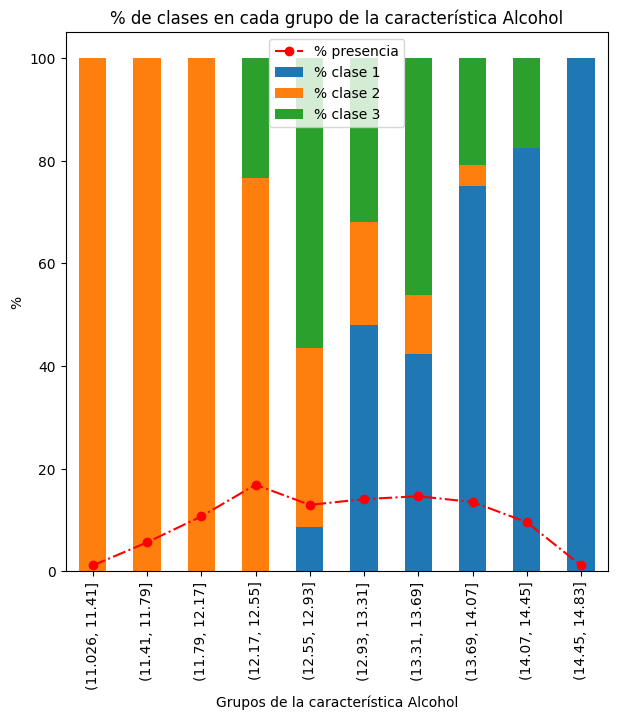

In [25]:
plot_num_feat(df_train_raw, 'Alcohol', bins = 10)

#### Malicacid
---
La variable malic acid presenta una distribución amplia y dispersa, con bastantes valores extremos hacia niveles altos. Los vinos con valores bajos (menores a 2) tienden a pertenecer a la clase 1 y 2, mientras que los valores altos reflejan claramente la predominancia de la clase 3.

No se observa un comportamiento estrictamente lineal, sino más bien zonas estables de predominio leve de ciertas clases.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


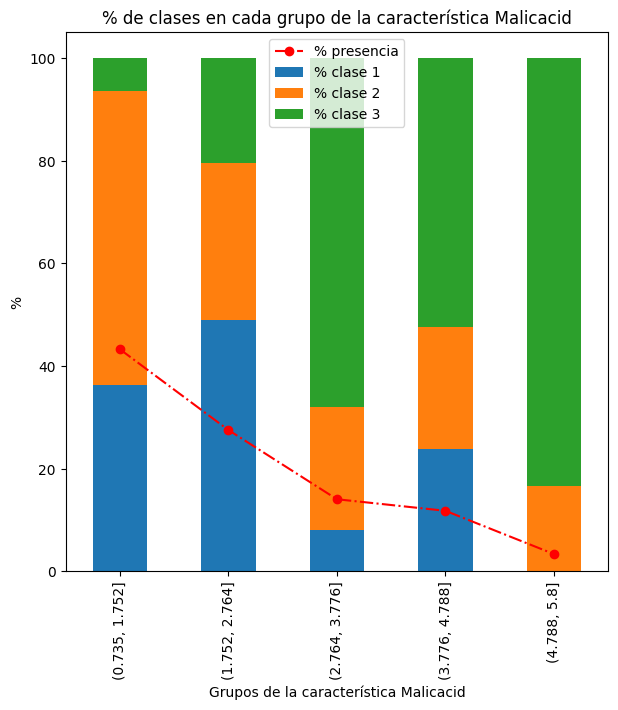

In [26]:
plot_num_feat(df_train_raw, 'Malicacid', 5)

#### Ash
---
La variable ash presenta una distribución compacta, sin valores atípicos fuertes. Se aprecia que los valores más bajos (1.3-2.0) favorecen levemente a la clase 2, pero las diferencias no son muy marcadas en valore superiores a 2.

La presencia de clases es bastante homogénea a través de todos los valores superiores a 2, lo que indica una baja capacidad discriminativa individual.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


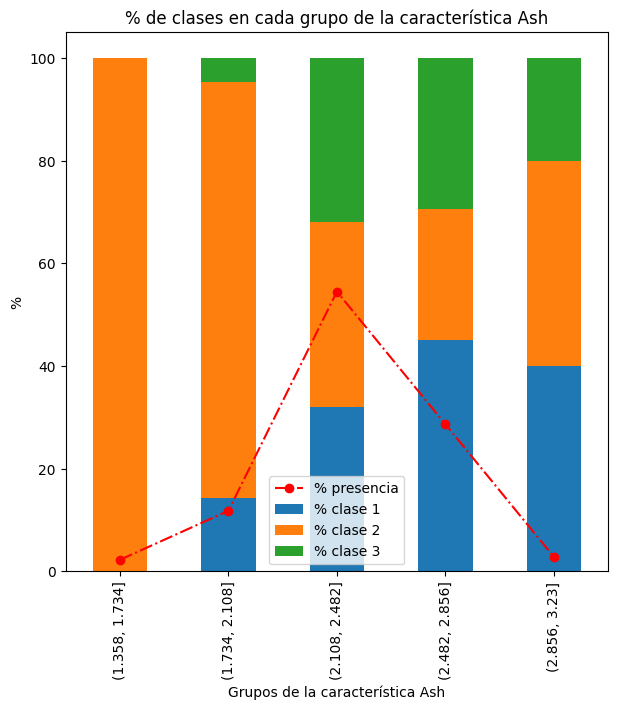

In [27]:
plot_num_feat(df_train_raw, 'Ash', 5)

#### Alcalinity_of_ash
---
Alcalinity of ash tiene un rango de valores amplio y muestra una ligera tendencia: los valores bajos (10-15) son más frecuentes en la clase 1, mientras que valores intermedios (15-25) no discriminan claramente. Existen algunos valores atípicos hacia valores altos. A partir del 25, se puede ver una evidente predominancia de la clase 2.

No se observa una relación lineal, sino más bien una separación parcial en los extremos.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


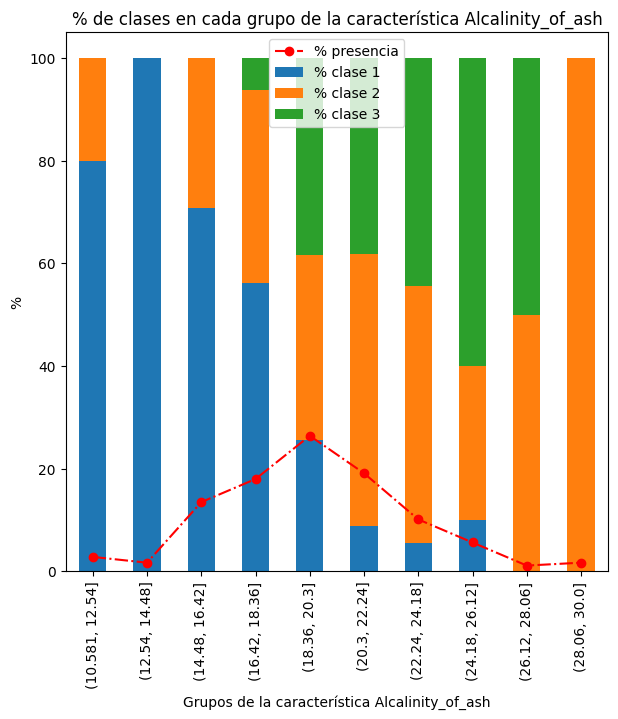

In [28]:
plot_num_feat(df_train_raw, 'Alcalinity_of_ash', 10)

#### Magnesium
---
La variable magnesium tiene una distribución razonablemente simétrica, aunque con algunos valores elevados considerados atípicos.

Los niveles bajos (70-100) presentan casi toda la muestra de la clase 3, mientras que los intermedios (80-150) son los que prevalencen para la clas 1. La clase 2 se ve distribuida casi uniformemente a lo largo de toda la variable.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


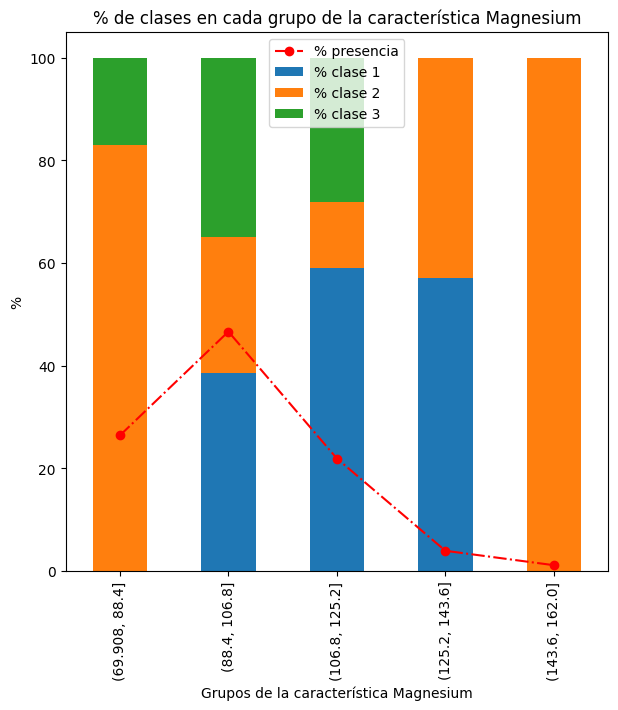

In [29]:
plot_num_feat(df_train_raw, 'Magnesium', 5)

#### Total_Phenols
---
Total phenols muestra una relación clara: vinos con altos niveles de fenoles totales (mayores a 2.5) tienden a pertenecer abrumadoramente a la clase 1.
Los valores bajos (menores a 1.5) favorecen clases 2 y 3.

No se detectan outliers preocupantes.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


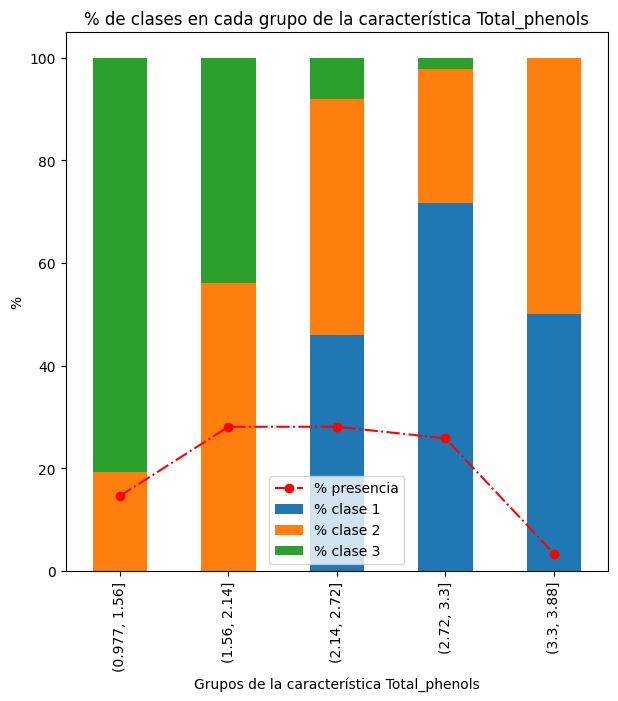

In [30]:
plot_num_feat(df_train_raw, 'Total_phenols', 5)

#### Flavanoids
---
La variable flavanoids presenta un comportamiento muy similar al de total phenols, aunque de forma aún más marcada.

Niveles altos (más de 3) se asocian casi exclusivamente a clase 1.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


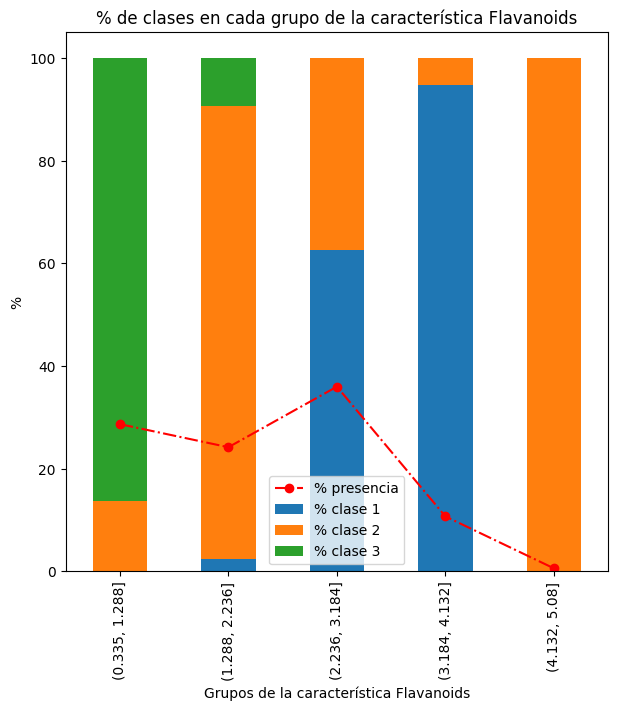

In [31]:
plot_num_feat(df_train_raw, 'Flavanoids', 5)

#### Nonflavanoid_phenols
---
Nonflavanoid phenols tiene un rango muy estrecho y una distribución menos discriminativa. Sin embargo, valores elevados (>0.5) tienden a asociarse ligeramente a clase 2 y 3.

Los niveles intermedios y bajos no permiten separación clara.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


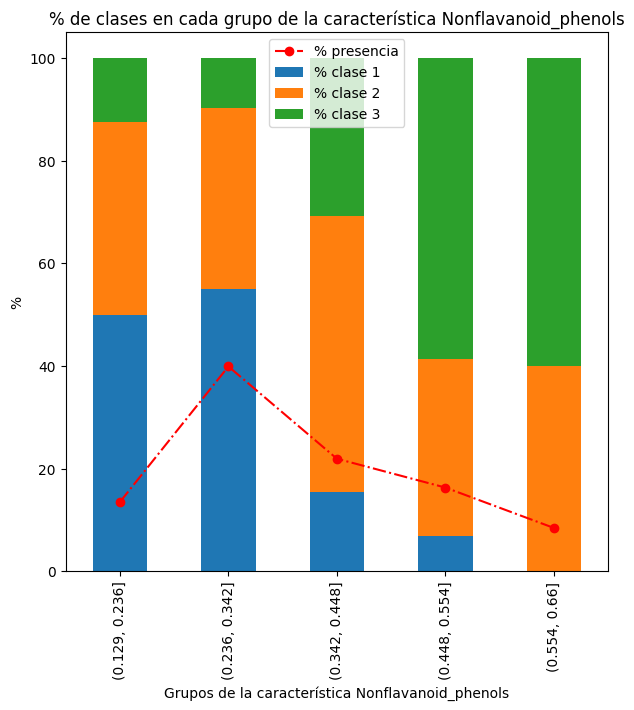

In [32]:
plot_num_feat(df_train_raw, 'Nonflavanoid_phenols', 5)

#### Proanthocyanins
---
La variable proanthocyanins muestra una clara separación entre las clases 1 y 3 a partir de valores rondando el 2.

La clase 2 está presente uniformemente casi en la totalidad de la muestra.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


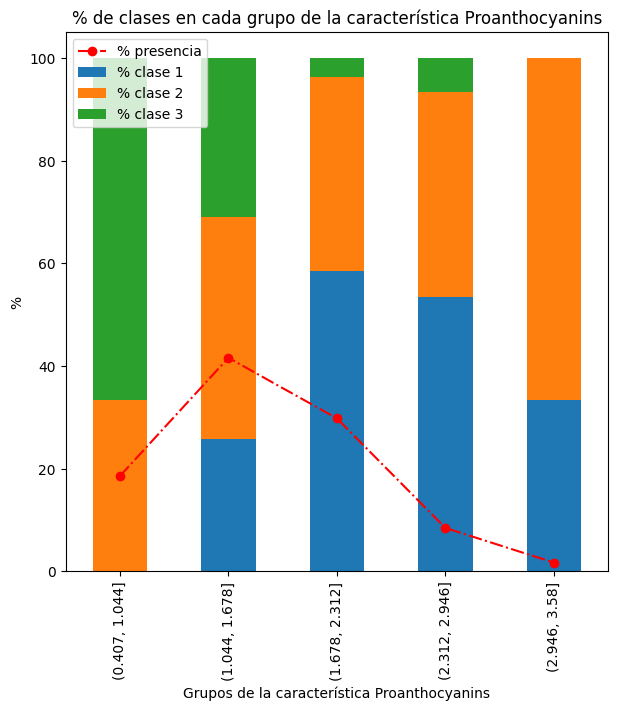

In [33]:
plot_num_feat(df_train_raw, 'Proanthocyanins', 5)

#### Color_intensity
---
Color intensity presenta una separación evidente: vinos con coloraciones más intensas (mayores a 6) son mayoritariamente de la clase 3.

La clase 1 domina en valores intermedios, mientras que la clase 2 predomina en colores menos intensos (<3).

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


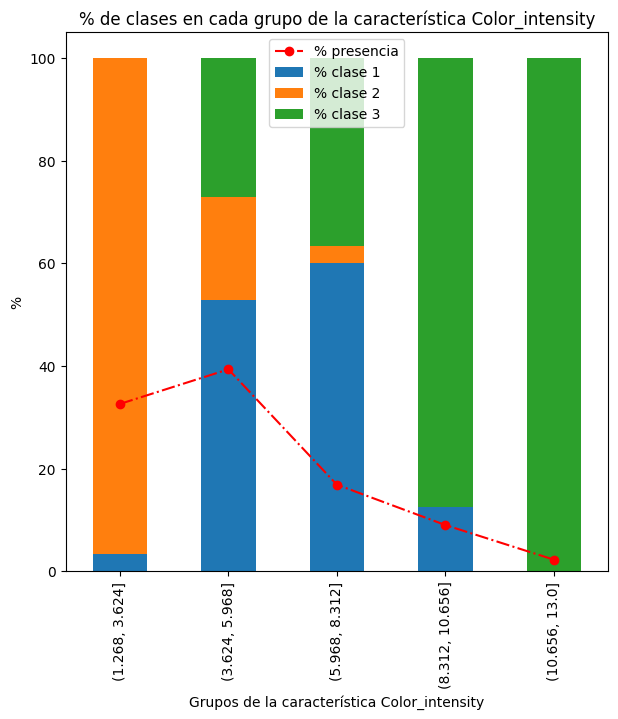

In [34]:
plot_num_feat(df_train_raw, 'Color_intensity', 5)

#### Hue
---
La variable Hue presenta un comportamiento similar al de la coloración, pero intercambiando la clase 3 por la 2, y manteniendo el comportamiento de la clase 1.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


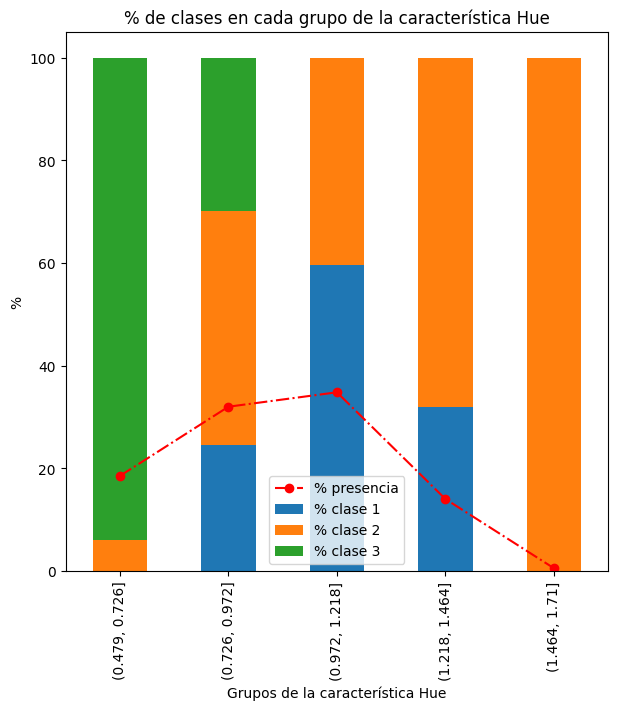

In [35]:
plot_num_feat(df_train_raw, 'Hue', 5)

#### 0D280_0D315_of_diluted_wines
---
La variable OD280/OD315 es muy buena discriminadora: valores altos (por encima de 2.8) concentran la mayoría de la clase 1, mientras que valores bajos están más asociados a clase 3.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


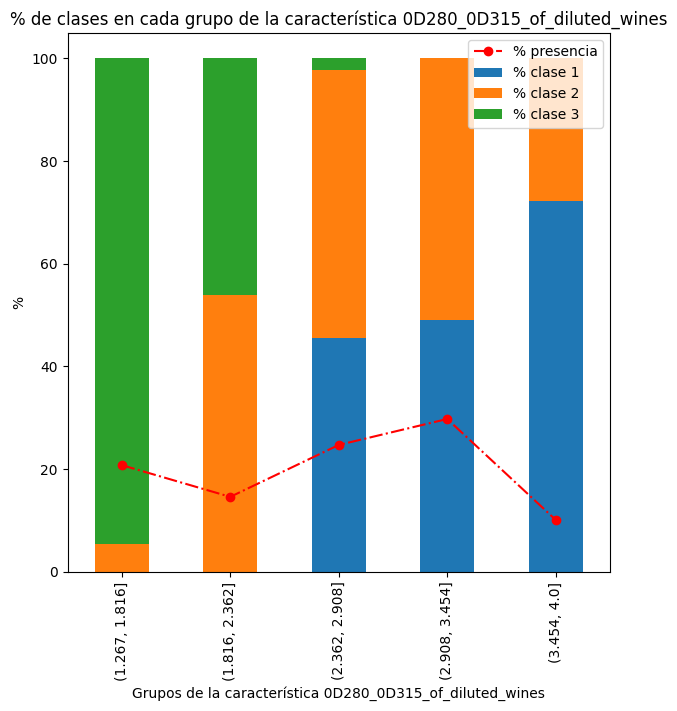

In [36]:
plot_num_feat(df_train_raw, '0D280_0D315_of_diluted_wines', 5)

#### Proline
---
La variable proline destaca como la mejor separadora: niveles bajos (menos de 600) son casi exclusivos de clase 2, intermedios de clase 3, y niveles muy altos (>1200) son dominio absoluto de la clase 1.

---

/var/folders/ml/2w_xpfqn40bcx06mm6kpz4p80000gn/T/ipykernel_19592/3463525267.py:23: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df_grouped = df_binned.groupby('bins')['target'].value_counts(normalize=True).unstack(fill_value=0) * 100


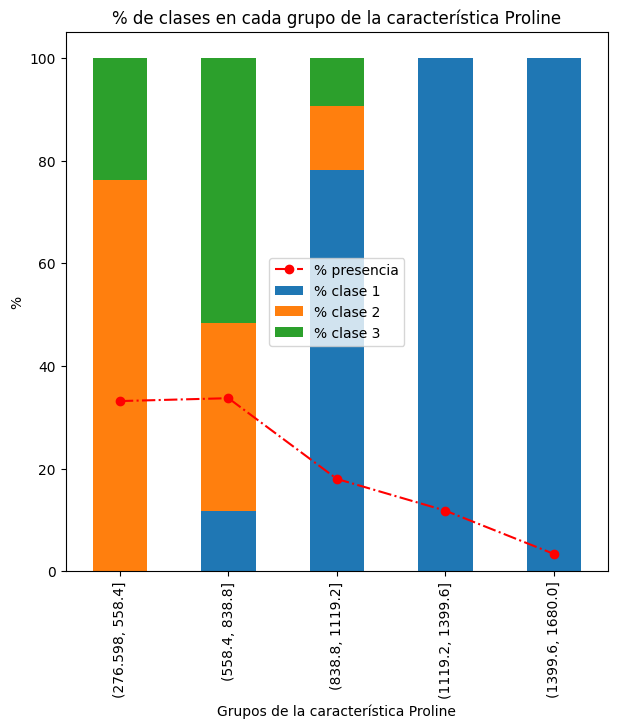

In [37]:
plot_num_feat(df_train_raw, 'Proline', 5)

# 2 - Procesado e ingeniería de características
---
En este punto, se realiza el procesado previo a la ingeniería de características, y la ingeniería de características propiamente dicha. Esta ingeniería de características se ha realizado utilizando la información y los insights obtenidos del EDA, y se han tomado las siguientes decisiones:

Una descripción más detallada de cada función se puede encontrar en su definición.

---

In [38]:
def target_encoding_calcuator(df, feat, target, threshold=0):
  '''
  Esta función se encarga de calcular el target encoding de una variable
  categórica dada.

  Parámetros de entrada:
    - df: dataframe en el que se encuentran los datos a analizar.
    - feat: nombre de la característica a procesar.
    - target: nombre de la variable objetivo
    - threshold: número mínimo de ocurrencias de una categoría para que no sea
    agrupada e imputada como nulo

  Parámetros de salida:
    - df: dataframe con la nueva variable procesada.

  '''

  print('Procesando la variable ' + feat)

  # En primer lugar, imputamos como nulas todas las categorías con presencia
  # inferior al threshold.
  if threshold > 0:
      df.loc[df[feat].isin(df[feat].value_counts().index[(df[feat].value_counts() < threshold)]),feat] = np.nan

  # Calculamos un diccionario con el mapeo de cada categoría con su % de clase 1
  unique_feat = df[feat].value_counts().index.to_list()
  feat_target = [df.loc[df[feat] == i, target].mean() for i in unique_feat]
  Map_feat_target = dict(zip(unique_feat, feat_target))

  # Definimos la nueva característica con el sufijo TE (Target Encoding)
  df[feat + '_TE'] = df[feat].map(Map_feat_target).astype(float)

  print('La variable ' + feat + ' de ha procesado correctamente')

  # Retornamos el dataframe con la variable procesada.
  return df

In [39]:
def target_encoding_num_groups(df, feat, target, bins, threshold = 0):
  '''
  Esta función se encarga de calcular el target encoding de una agrupación dada
  de una variable numérica.

  Parámetros de entrada:
    - df: dataframe en el que se encuentran los datos a analizar.
    - feat: nombre de la característica a procesar.
    - target: nombre de la variable objetivo.
    - bins: valor numérico con el número de particiones o lista con los puntos
    de corte deseados para la variable numérica.
    - threshold: número mínimo de ocurrencias de una categoría para que no sea
    agrupada e imputada como nulo

  Parámetros de salida:
    - df: dataframe con la nueva variable procesada.

  '''

  # Creamos una nueva variabel categórica con las agrupaciones decididas.
  df[feat + '_bins'] = pd.cut(df[feat], bins = bins)

  # Calculamos el target encoding de esta nueva variable categórica.
  df = target_encoding_calcuator(df, feat + '_bins', target, threshold)
  df[feat + '_bins_TE'] = df[feat + '_bins_TE'].astype(float)

  # Retornamos el dataframe con la variable procesada.
  return df

In [40]:
def mean_norm_calculation(df, feat):
  '''
  Esta función se encarga de calcular la normalización de una variable numérica

  Parámetros de entrada:
    - df: dataframe en el que se encuentran los datos a analizar.
    - feat: nombre de la característica a procesar.

  Parámetros de salida:
  - df: dataframe con la nueva variable procesada.

  '''

  return (df[feat]-df[feat].mean())/df[feat].std()

In [41]:
# Copiamos el dataset original para no realizar transformaciones sobre este.
df_train = df_train_raw.copy()

## 2.1 - Procesado de los datos
---

## 2.2 - Ingeniería de características
---
En este paso, se realiza la ingeniería de características de todas las variables. Para ello, valiéndonos de las funciones, se definen tres diccionarios con la información de las transformaciones a realizar.

---

In [49]:
# Diccionario con información de las transformaciones a realizar para las
# variables numéricas (target encoding)
num_feats2TE = {
    "Alcohol": 10,
    "Malicacid": 5,
    "Ash": 5,
    "Alcalinity_of_ash": 10,
    "Magnesium": 5,
    "Total_phenols": 5,
    "Flavanoids": 5,
    "Total_phenols": 5,
    "Nonflavanoid_phenols": 5,
    "Proanthocyanins": 5,
    "Color_intensity": 5,
    "Hue": 5,
    "0D280_0D315_of_diluted_wines": 5,
    "Proline": 5
}

# Lista con las características numéricas a normalizar
feats2norm = ['Alcohol',
            'Malicacid',
            'Ash',
            'Alcalinity_of_ash',
            'Magnesium',
            'Total_phenols',
            'Flavanoids',
            'Nonflavanoid_phenols',
            'Proanthocyanins',
            'Color_intensity',
            'Hue',
            '0D280_0D315_of_diluted_wines',
            'Proline']

### 2.2.1 - Ingeniería de características numéricas
---
Para cada característica numérica, se realizan las tres transformaciones descritas, según el caso. Las decisiones tomadas para estas transformaciones se basan en el EDA realizado, y las iteraciones de entrenamientos durante el desarrollo de este proyecto

---

In [44]:
for k, v in num_feats2TE.items():
  df_train = target_encoding_num_groups(df_train, k, 'target', v)

Procesando la variable Alcohol_bins
La variable Alcohol_bins de ha procesado correctamente
Procesando la variable Malicacid_bins
La variable Malicacid_bins de ha procesado correctamente
Procesando la variable Ash_bins
La variable Ash_bins de ha procesado correctamente
Procesando la variable Alcalinity_of_ash_bins
La variable Alcalinity_of_ash_bins de ha procesado correctamente
Procesando la variable Magnesium_bins
La variable Magnesium_bins de ha procesado correctamente
Procesando la variable Total_phenols_bins
La variable Total_phenols_bins de ha procesado correctamente
Procesando la variable Flavanoids_bins
La variable Flavanoids_bins de ha procesado correctamente
Procesando la variable Nonflavanoid_phenols_bins
La variable Nonflavanoid_phenols_bins de ha procesado correctamente
Procesando la variable Proanthocyanins_bins
La variable Proanthocyanins_bins de ha procesado correctamente
Procesando la variable Color_intensity_bins
La variable Color_intensity_bins de ha procesado correcta

In [50]:
for i in feats2norm:
  df_train[i + '_mean_norm'] = mean_norm_calculation(df_train, i)

# 3 - Modelado
---
Una vez construido el dataset, se procede al entrenamiento de un modelo de Machine Learning.

Con todo lo aprendido anteriormente de los datos, tratándose de un **problema de clasificación binaria**, con un dataset **desbalanceado**, un pequeño grupo de características a utilizar y claras agrupaciones que pueden ayudar en la decisión de la clase final, se ha decidido optar por un **XGBoost** como modelo para este proyecto.

La decisión se ha tomado por la demostrada eficiencia de estos modelos en los problemas de clasificación binaria, en el tratamiento de datasets desbalanceados y en la capacidad de tratamiento de datos nulos como información desconocida.

---

In [51]:
df_train.columns.to_list()

['Alcohol',
 'Malicacid',
 'Ash',
 'Alcalinity_of_ash',
 'Magnesium',
 'Total_phenols',
 'Flavanoids',
 'Nonflavanoid_phenols',
 'Proanthocyanins',
 'Color_intensity',
 'Hue',
 '0D280_0D315_of_diluted_wines',
 'Proline',
 'target',
 'Alcohol_bins',
 'Alcohol_bins_TE',
 'Malicacid_bins',
 'Malicacid_bins_TE',
 'Ash_bins',
 'Ash_bins_TE',
 'Alcalinity_of_ash_bins',
 'Alcalinity_of_ash_bins_TE',
 'Magnesium_bins',
 'Magnesium_bins_TE',
 'Total_phenols_bins',
 'Total_phenols_bins_TE',
 'Flavanoids_bins',
 'Flavanoids_bins_TE',
 'Nonflavanoid_phenols_bins',
 'Nonflavanoid_phenols_bins_TE',
 'Proanthocyanins_bins',
 'Proanthocyanins_bins_TE',
 'Color_intensity_bins',
 'Color_intensity_bins_TE',
 'Hue_bins',
 'Hue_bins_TE',
 '0D280_0D315_of_diluted_wines_bins',
 '0D280_0D315_of_diluted_wines_bins_TE',
 'Proline_bins',
 'Proline_bins_TE',
 'Alcohol_mean_norm',
 'Malicacid_mean_norm',
 'Ash_mean_norm',
 'Alcalinity_of_ash_mean_norm',
 'Magnesium_mean_norm',
 'Total_phenols_mean_norm',
 'Flavano

In [78]:
# Declaramos las características a utilizar en el entrenamiento del modelo, así
# como el target del mismo.
feats2use = [
'Alcohol',
'Malicacid',
'Ash',
'Alcalinity_of_ash',
'Magnesium',
'Total_phenols',
'Flavanoids',
'Nonflavanoid_phenols',
'Proanthocyanins',
'Color_intensity',
'Hue',
'0D280_0D315_of_diluted_wines',
'Proline',
'Alcohol_bins_TE',
'Malicacid_bins_TE',
'Ash_bins_TE',
'Alcalinity_of_ash_bins_TE',
'Magnesium_bins_TE',
'Total_phenols_bins_TE',
'Flavanoids_bins_TE',
'Nonflavanoid_phenols_bins_TE',
'Proanthocyanins_bins_TE',
'Color_intensity_bins_TE',
'Hue_bins_TE',
'0D280_0D315_of_diluted_wines_bins_TE',
'Proline_bins_TE',
'Alcohol_mean_norm',
'Malicacid_mean_norm',
'Ash_mean_norm',
'Alcalinity_of_ash_mean_norm',
'Magnesium_mean_norm',
'Total_phenols_mean_norm',
'Flavanoids_mean_norm',
'Nonflavanoid_phenols_mean_norm',
'Proanthocyanins_mean_norm',
'Color_intensity_mean_norm',
'Hue_mean_norm',
'0D280_0D315_of_diluted_wines_mean_norm',
'Proline_mean_norm',
'target'
]

In [79]:
# Realizamos la selección de las características a utilizar del dataset
# procesado
df_FM_train = df_train[feats2use].copy()

In [80]:
df_FM_train

,Alcohol,Malicacid,Ash,Alcalinity_of_ash,Magnesium,Total_phenols,Flavanoids,Nonflavanoid_phenols,Proanthocyanins,Color_intensity,Hue,0D280_0D315_of_diluted_wines,Proline,Alcohol_bins_TE,Malicacid_bins_TE,Ash_bins_TE,Alcalinity_of_ash_bins_TE,Magnesium_bins_TE,Total_phenols_bins_TE,Flavanoids_bins_TE,Nonflavanoid_phenols_bins_TE,Proanthocyanins_bins_TE,Color_intensity_bins_TE,Hue_bins_TE,0D280_0D315_of_diluted_wines_bins_TE,Proline_bins_TE,Alcohol_mean_norm,Malicacid_mean_norm,Ash_mean_norm,Alcalinity_of_ash_mean_norm,Magnesium_mean_norm,Total_phenols_mean_norm,Flavanoids_mean_norm,Nonflavanoid_phenols_mean_norm,Proanthocyanins_mean_norm,Color_intensity_mean_norm,Hue_mean_norm,0D280_0D315_of_diluted_wines_mean_norm,Proline_mean_norm,target
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1.352941,1.701299,2.000000,1.291667,1.428571,1.304348,1.375000,1.549296,1.452830,1.742857,1.403226,1.277778,1.3125,1.514341,-0.560668,0.231400,-1.166303,1.908522,0.806722,1.031908,-0.657708,1.221438,0.251009,0.361158,1.842721,1.010159,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1.840000,1.714286,2.000000,1.200000,1.963855,1.620000,1.375000,1.549296,2.054054,1.742857,1.403226,1.509434,1.3125,0.245597,-0.498009,-0.825667,-2.483841,0.018094,0.567048,0.731565,-0.818411,-0.543189,-0.292496,0.404908,1.110317,0.962526,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1.840000,1.714286,1.843137,2.127660,1.963855,1.304348,1.052632,1.549296,1.533333,1.742857,1.403226,1.509434,1.0000,0.196325,0.021172,1.106214,-0.267982,0.088110,0.806722,1.212114,-0.497005,2.129959,0.268263,0.317409,0.786369,1.391224,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1.352941,1.714286,1.843137,1.500000,1.692308,1.500000,1.052632,1.549296,1.452830,1.766667,2.052632,1.509434,1.0000,1.686791,-0.345835,0.486554,-0.806975,0.928300,2.484437,1.462399,-0.979113,1.029251,1.182732,-0.426341,1.180741,2.328007,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1.840000,1.714286,1.800000,2.294118,1.692308,1.304348,1.375000,2.153846,1.452830,1.742857,1.403226,1.509434,2.4000,0.294868,0.227053,1.835226,0.450674,1.278379,0.806722,0.661485,0.226158,0.400275,-0.318377,0.361158,0.448336,-0.037767,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740,1.458333,2.833333,2.000000,2.294118,1.963855,2.440000,2.862745,2.517241,2.054054,1.766667,2.939394,2.945946,2.4000,0.873810,2.966176,0.304301,0.300954,-0.331985,-0.982841,-1.420891,1.270726,-0.927563,1.139596,-1.388840,-1.227742,-0.021890,3
174,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750,2.038462,2.285714,2.000000,2.388889,1.963855,2.440000,2.862745,2.153846,2.054054,1.766667,2.939394,2.945946,2.4000,0.491955,1.408636,0.413653,1.049555,0.158126,-0.791103,-1.280731,0.547563,-0.316058,0.967055,-1.126341,-1.481267,0.009866,3
175,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835,1.840000,2.285714,2.000000,2.127660,1.692308,2.440000,2.862745,2.153846,2.054054,2.750000,2.939394,2.945946,2.4000,0.331822,1.739837,-0.388260,0.151234,1.418411,-1.126646,-1.340800,0.547563,-0.420888,2.217979,-1.607590,-1.481267,0.279786,3
176,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840,1.840000,1.714286,2.000000,2.127660,1.692308,2.440000,2.862745,2.517241,2.054054,2.750000,2.939394,2.945946,1.3125,0.208643,0.227053,0.012696,0.151234,1.418411,-1.030776,-1.350811,1.351077,-0.228701,1.829761,-1.563840,-1.396759,0.295664,3


## 3.1 - Definición de los datasets de entrenamiento y evaluación del modelo

In [81]:
# Definimos las columans con las características, eliminando la columan target.
columns_x = df_FM_train.columns.drop('target')

In [82]:
# Definimos las variables X e y, con los datos de entrenamiento y la variable
# objetivo, respectivamente.
X = df_FM_train[columns_x]
y = df_FM_train['target']

In [83]:
# Dividimos el dataset en entrenamiento y evaluación (80% - 20% respectivamente)
X_train, X_test,  y_train, y_test= train_test_split(X, y,
                                                    train_size=0.8,
                                                    test_size=0.2,
                                                    random_state=0)

In [84]:
y_train = y_train - 1
y_test = y_test - 1

In [85]:
# Para el xgboost, se declara una DMatrix con los datos de entrenamiento
xgtrain = xgb.DMatrix(X_train.values, y_train.values)

In [86]:
# Para el xgboost, se declara una DMatrix con los datos de evaluación
xgtest = xgb.DMatrix(X_test.values, y_test.values)

## 3.2 - Entrenamiento del modelo
---
En este punto, se entrena el modelo. Nótese que los hiperparámetros elegidos
se han tomado tras varias iteraciones de un proceso de búsqueda de hiperparámetros reticular, descrito más adelante. Si bien es cierto que puede realizarse una búsqueda de mayor profundidad de cara a obtener mejores resultados, los resultados obtenidos han resultado ser satisfactorios para el marco de este proyecto.

En la [documentación oficial](https://xgboost.readthedocs.io/en/stable/parameter.html) de XGBoost se encuentra información detallada de los hiperparámetros utilizados.

---

In [87]:
# Definimos los parámetros de entrada a la función de entrenamiento del modelo.
evallist = [(xgtrain, 'train'), (xgtest, 'eval')]

num_round = 1000

param = {
        'max_depth': 10,
        'eta': 0.01,
        'objective': 'multi:softprob',  # or 'multi:softmax'
        'num_class': 3,
        'eval_metric': 'mlogloss',
        'max_delta_step': 1,
        'min_child_weight': 6,
        'gamma': 0.1,
        'nthread': 4,
        'eval_metric': 'auc'
        }

In [88]:
# Entrenamos el modelo final.
xgb_model = xgb.train(
    params=param,
    dtrain=xgtrain,
    num_boost_round=num_round,
    evals=evallist
)

[0]	train-auc:0.99528	eval-auc:0.95391
[1]	train-auc:0.99527	eval-auc:0.97266
[2]	train-auc:0.99535	eval-auc:0.97266
[3]	train-auc:0.99527	eval-auc:0.97266
[4]	train-auc:0.99535	eval-auc:0.97266
[5]	train-auc:0.99527	eval-auc:0.97266
[6]	train-auc:0.99535	eval-auc:0.97266
[7]	train-auc:0.99527	eval-auc:0.97266
[8]	train-auc:0.99535	eval-auc:0.97266
[9]	train-auc:0.99551	eval-auc:0.97266
[10]	train-auc:0.99594	eval-auc:0.97266
[11]	train-auc:0.99611	eval-auc:0.97266
[12]	train-auc:0.99611	eval-auc:0.97266
[13]	train-auc:0.99625	eval-auc:0.97266
[14]	train-auc:0.99625	eval-auc:0.97266
[15]	train-auc:0.99640	eval-auc:0.97174
[16]	train-auc:0.99671	eval-auc:0.97134
[17]	train-auc:0.99773	eval-auc:0.97134
[18]	train-auc:0.99766	eval-auc:0.97134
[19]	train-auc:0.99766	eval-auc:0.97134
[20]	train-auc:0.99787	eval-auc:0.97134
[21]	train-auc:0.99802	eval-auc:0.97134
[22]	train-auc:0.99819	eval-auc:0.97399
[23]	train-auc:0.99819	eval-auc:0.97399
[24]	train-auc:0.99819	eval-auc:0.97492
[25]	train

## 3.3 - Búsqueda reticular de hiperparámetros
---
En este punto, se ha desarrollado una función para la búsqueda reticular de hiperparámetros realizando un entrenamiento de validación cruzada.

Esta función, inspirada en la función de funcionamiento análogo de [sklearn](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html), elige, dentro de un hiperespacio de hiperparámetros definido en un diccionario, un conjunto de dichos hiperparámetros de forma aleatoria, entrena un modelo validándolo de forma cruzada, y se queda, tras un número de iteraciones definidas por el usuario, con el conjunto de hiperparámetros que mejor resultados ha dado para la métrica a optimizar definida por el usuario.

Una descripción más detallada del funcionamiento de la función se puede ver en la definición de la misma.

---

In [ ]:
# Declaración del hiperespacio de hiperparámetros a utilizar en la búsqueda.
parameters_pre_FS = {
    'learning_rate': [0.05, 0.1, 0.2, 0.3],
    'max_depth': [9, 12, 15],
    'min_child_weight': [1, 3, 5, 10],
    'gamma': [0, 0.1, 0.2, 0.3, 0.4],
    'reg_alpha': [0, 0.001, 0.01, 0.1, 1, 10],
    'reg_lambda': [0, 0.001, 0.01, 0.1, 1, 10],
    'nthread': [4],
    'eval_metric': ['auc']
}

In [ ]:
def RandGridsearchCV(param, xgtrain, num_round = 1000, niter = 100, cross_val = 5, seed = 0):
  '''
  Esta función realiza una búsqueda aleatoria de hiperparámetros en un
  hiperespacio de hiperparámetros dado, y devuelve el conjunto de
  hiperparámetros que mejores resultados ha dado, utilizando un proceso de
  validación cruzada.

  Parámetros de entrada:
  - param: hiperespacio con los hiperparámetros en el que realizar la búsqueda.
  - xgtrain: dataset de entrenamiento.
  - num_round: número de árboles de cada iteración.
  - niter: número de iteraciones o conjuntos de hiperparámetros a probar.
  - cross_val: número de pliegues para el proceso de validación cruzada.
  - seed: semilla aleatoria del proceso de validación cruzada.

  Parámetros de salida:
  - selected_params: los mejores hiperparámetros obtenidos.


  '''
  max_auc = 0
  selected_params = None

  # Hacemos tantas selecciones aleatorias como decida el usuario.
  for i in range(niter):
    print("Prueba número: " + str(i))

    # Creamos un diccionario con el set de hiperparámetros a probar
    sub_params = {k: random.sample(v,1)[0] for k,v in param.items()}

    # Realizamos el entrenamiento con validación cruzada
    cv_model = xgb.cv(sub_params, xgtrain, num_round, cross_val, seed)

    # Obtenemos el mejor área bajo la curva AUC de esta iteración.
    best_auc = cv_model['test-auc-mean'].max()
    print("El mejor ROC AUC para esta iteración ha sido: " + str(best_auc))
    print("Los hiperparámetros utilizados han sido: " + str(sub_params))

    # Si el área bajo la curva AUC ha mejorado, lo guardamos como el mejor,
    # así como los hiperparámetros asociados.
    if best_auc > max_auc:
      max_auc = best_auc
      selected_params = sub_params

  # Retornamos los mejores hiperparámetrso obtenidos.
  print("El mejor ROC AUC Score obtenido es: " + str(max_auc))
  print("Los parámetros elegidos son " + str(selected_params))
  return selected_params

### 3.3.1 - Proceso iterativo de búsqueda
---
Este proceso iterativo ha sido utilizado para la elección del modelo. Queda a discreción del usuario repetirlo. Nótese que es un proceso largo. Si se quiere ver el funcionamiento de la función, se recomienda reducir el número de iteraciones.

---

In [ ]:
best_params = RandGridsearchCV(parameters_pre_FS, xgtrain, num_round = 1000, niter = 10, cross_val = 5, seed = 0)

### 3.3.2 - Impresión por pantalla de los mejores hiperparámetros encontrados

In [ ]:
best_params

# 4 - Evaluación del modelo obtenido
---
En este último punto, procedemos a evaluar el modelo entrenado. Para ello, como ya se ha comentado anteriormente, no nos valdremos únicamente del accuracy, al tratarse de un dataset desbalanceado. En contra, nos centraremos en métricas como la precisión, el recall y el área bajo la curva ROC.

Además, se representa la matriz de confusión para los datos de evaluación.

---

In [89]:
# Obtenemos la predicción del modelo y el "ground truth"

y_pred_aux = xgb_model.predict(xgtest)
y_pred_test=np.argmax(y_pred_aux,axis=1)
y_true_test = y_test

## 4.1 - Obtención de las métricas más relevantes del modelo

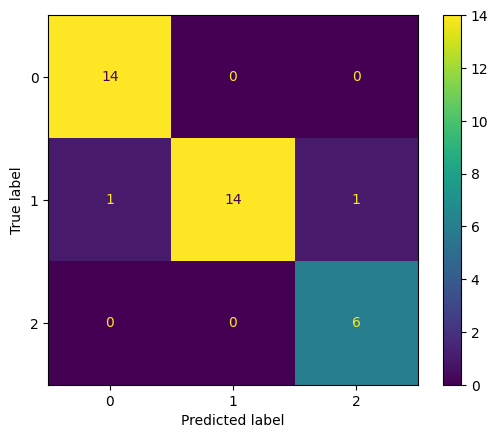


ACCURACY: 94.44%


In [91]:
cm = confusion_matrix(y_true_test, y_pred_test)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.show()

print()

print("ACCURACY: " + str("{:.2f}".format(accuracy_score(y_true_test, y_pred_test) * 100)) + '%')

---
En resumen, obtenemos un modelo con una accuracy del 87%, un área bajo la curva ROC del 0.93, una precisión del 77% y un recall del 65%. Si bien es cierto que no son resultados extraordinarios, el modelo entrenado es un modelo robusto, sin overfitting, capaz de detectar un gran número de usuarios con clase 1 (elevada precision), aunque erra ocasionalmente, pasando por alto usuarios con clase 1 (no tan elevado recall).

Concluimos que el modelo entrenado tiene unos resultados satisfactorios.

---

## 4.2 - Obtención de la importancia de las características utilizadas en el modelo entrenado

---
De cara a un análisis posterior, se imprimen por pantalla las características con las que se ha entrenado el modelo, ordenadas de mayor a menor importancia para dicho intrenamiento.

---

Text(0.5, 0, 'Xgboost Feature Importance')

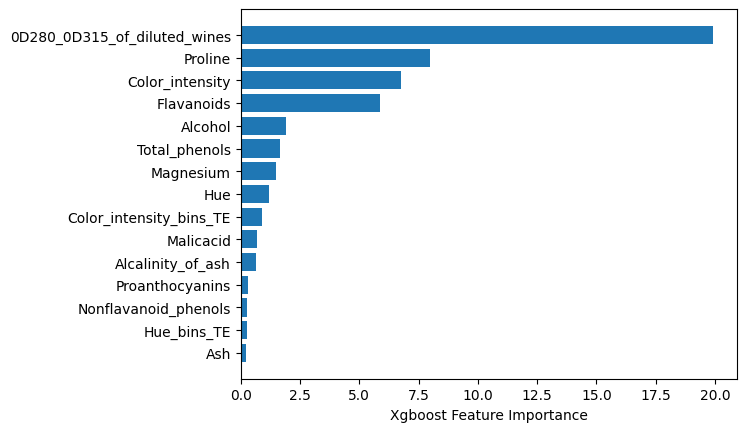

In [92]:
feat_importance = {int(k.replace('f','')): v for k, v in xgb_model.get_score(importance_type='gain').items()}

df_featimp = pd.DataFrame(list(feat_importance.values()), index = list(feat_importance)).sort_values(0)

plt.barh(X.columns[df_featimp.index], df_featimp[0])
plt.xlabel("Xgboost Feature Importance")

---
Como ya se había comentado durante el EDA, las variables "relationship", "marital-status" y "education-num" son de gran importancia para el modelo. Asimismo, cabe destacar que las variables "capital-gain" y "capital-loss" son también muy importantes debido a la notable presencia de outliers en estas.

Por último, las variables redundates como "education" o la agrupación de "capital-gain", "capital-loss" o "fnlwgt" no son relevantes para el modelo, como tampoco lo son las variables con gran cantidad de categorías minoritarias, como "race" o "native-country".

---

# 5 - Conclusión
---
En este Notebook, se ha realizado un EDA en profundidad del dataset dispuesto, en el que se han analizado tanto variables numéricas como categóricas con el fin de encontrar tendencias, anomalías y lograr tomar decisiones lógicas para el entrenamiento de un modelo predictivo.

Se ha decidido relaizar una ingeniería de características exhaustiva en la que ha destacado el target encoding como transformación fundamental, y la imputación de las categorías minoritarias como nans.

El modelo elegido, un XGBoost, se ha seleccionado por sus buenos resultados en problemas de clasificación binaria, su buena gestión de los datasets desbalanceados y la capacidad de aceptar nulos como valores de entrada.

Los resultados obtenidos reflejan la capacidad del modelo para predecir correctamente la clase positiva, con un accuracy superior al 87%, y una precisión superior al 77%.

---